<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/17_BERT_GPT_Fine_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Modelos preentrenados y fine-tuning: BERT y GPT</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Preentrenamiento</span>](#preentrenamiento)
- [<span style="color: #005C99;">Tokenización en subpalabras</span>](#tokenizacion-en-subpalabras)
- [<span style="color: #005C99;">BERT</span>](#bert)
- [<span style="color: #005C99;">GPT</span>](#gpt)
- [<span style="color: #005C99;">Hugging Face Hub</span>](#hugging-face-hub)
- [<span style="color: #005C99;">Fine-tuning para clasificación</span>](#fine-tuning-para-clasificacion)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

> **GPU recomendada.** Este cuaderno descarga y ejecuta modelos de cientos de millones de parámetros. En Google Colab activa una GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*. El código también funciona en CPU, pero mucho más lento.

> **Sobre el framework.** Desde la versión 5, la librería `transformers` de Hugging Face solo funciona con **PyTorch** (abandonó TensorFlow y JAX). Por eso, a partir de este cuaderno los modelos preentrenados se cargan con PyTorch; las ideas son las mismas que en Keras y casi todo el código usa la interfaz de alto nivel de `transformers`.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn datasets "transformers>=5" accelerate torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import transformers
from transformers import AutoTokenizer, pipeline, set_seed
from transformers import AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
set_seed(SEED)  # fija las semillas de Python, NumPy y PyTorch
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print(f"transformers {transformers.__version__} | PyTorch {torch.__version__} | dispositivo: {dispositivo}")

transformers 5.20.2 | PyTorch 2.11.0+cu128 | dispositivo: cuda


<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

Hasta ahora, cada modelo se entrenaba **desde cero** para una tarea: los embeddings, las capas recurrentes o convolucionales y el clasificador aprendían solo de las reseñas etiquetadas. En el cuaderno 12 dimos un primer paso hacia el **aprendizaje por transferencia**: preentrenar embeddings (Word2Vec, GloVe) con texto sin etiquetar y reutilizarlos. Pero esos embeddings son **estáticos** (un vector por palabra, sin contexto) y solo transfieren la primera capa del modelo.

Entre 2018 y 2019, varios trabajos mostraron que se podía transferir **el modelo completo**:

| Año | Modelo | Idea |
|---|---|---|
| 2018 | ELMo (Peters et al.) | Embeddings contextuales de una LSTM bidireccional preentrenada como modelo de lenguaje |
| 2018 | ULMFiT (Howard & Ruder) | Preentrenar un modelo de lenguaje y ajustarlo (*fine-tuning*) a la tarea |
| 2018 | GPT (Radford et al.) | Lo mismo con un decodificador Transformer |
| 2018 | BERT (Devlin et al.) | Codificador Transformer **bidireccional** preentrenado prediciendo palabras enmascaradas |
| 2020 | GPT-3 (Brown et al.) | Con suficiente escala, el modelo resuelve tareas **sin fine-tuning**, a partir de instrucciones y ejemplos en el texto (*in-context learning*) |

El paradigma resultante tiene dos fases:

1. **Preentrenamiento** (costoso, se hace una vez): un Transformer aprende un modelo del lenguaje con enormes cantidades de texto sin etiquetar.
2. **Fine-tuning** (barato): se ajustan todos los pesos con un conjunto etiquetado pequeño para la tarea concreta.

En este cuaderno estudiamos las dos familias principales, **BERT** (codificador) y **GPT** (decodificador), con modelos entrenados en español, y hacemos fine-tuning de BERT para la tarea de sentimiento de los cuadernos anteriores.

<a id="preentrenamiento"></a>
<h2 style="color: #007ACC;">Preentrenamiento</h2>

El preentrenamiento es **autosupervisado**: las etiquetas salen del propio texto, así que se puede usar todo el texto disponible en internet, libros, Wikipedia, etc. Los dos objetivos más comunes son:

- **Modelado de lenguaje causal** (GPT): predecir la siguiente palabra a partir de las anteriores, como los N-gramas del módulo 2 pero con un Transformer con máscara causal.

$$\mathcal{L}_{\text{CLM}} = -\sum_t \log P(w_t \mid w_1, \dots, w_{t-1})$$

- **Modelado de lenguaje enmascarado** (BERT): se ocultan al azar el 15 % de los tokens y el modelo los predice usando el contexto **a ambos lados**.

$$\mathcal{L}_{\text{MLM}} = -\sum_{t \in \text{enmascarados}} \log P(w_t \mid \text{oración con máscaras})$$

```text
Causal (GPT):        El  perro  ladra  al  →  ¿cartero?       solo ve la izquierda
Enmascarado (BERT):  El  perro  [MASK]  al  cartero  →  ¿ladra?   ve ambos lados
```

Para predecir bien la palabra que falta, el modelo necesita aprender sintaxis (concordancia, orden), semántica (qué palabras encajan), conocimiento del mundo (*"la capital de Colombia es ___"*) e incluso algo de razonamiento. Todo eso queda codificado en sus pesos y se aprovecha al ajustarlo a otra tarea.

La escala ha crecido varios órdenes de magnitud:

| Modelo | Año | Parámetros | Texto de preentrenamiento |
|---|---|---|---|
| BERT-base | 2018 | 110 millones | 3 300 millones de palabras (Wikipedia + libros, en inglés) |
| BETO (BERT en español) | 2020 | 110 millones | ~3 000 millones de palabras en español |
| GPT-2 | 2019 | 124 a 1 500 millones | 40 GB de páginas web |
| GPT-3 | 2020 | 175 000 millones | ~300 000 millones de tokens |
| Llama 3 | 2024 | 8 000 a 405 000 millones | ~15 billones de tokens |

Preentrenar BETO requirió varios días en TPU; un modelo como Llama 3 cuesta millones de dólares en cómputo. Por eso casi nunca se preentrena desde cero: se descargan modelos ya preentrenados de repositorios como el **Hugging Face Hub**.

<a id="tokenizacion-en-subpalabras"></a>
<h2 style="color: #007ACC;">Tokenización en subpalabras</h2>

Los modelos preentrenados no trabajan con palabras completas ni con caracteres, sino con **subpalabras**, como el BPE del cuaderno 01. Un vocabulario de subpalabras (normalmente de 30 000 a 150 000 unidades) tiene dos ventajas:

- **No hay palabras desconocidas:** una palabra rara se descompone en piezas conocidas (*desafortunadamente* → *desafortun* + *##adamente*).
- **El vocabulario es manejable:** las palabras frecuentes son un solo token y las raras varios.

Los algoritmos más usados son **WordPiece** (BERT, BETO), **BPE a nivel de bytes** (GPT-2, Llama, Qwen) y **Unigram/SentencePiece** (T5, mT5). Cada modelo trae su propio tokenizador, que hay que usar tal cual: el modelo solo entiende los identificadores de su vocabulario.

Comparemos tres tokenizadores: BETO, un GPT-2 entrenado con Wikipedia en español y el GPT-2 original, entrenado con texto en inglés.

In [3]:
tokenizadores = {
    "BETO (WordPiece, español)": AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased"),
    "GPT-2 español (BPE)": AutoTokenizer.from_pretrained("datificate/gpt2-small-spanish"),
    "GPT-2 original (BPE, inglés)": AutoTokenizer.from_pretrained("openai-community/gpt2"),
}

frase = "La Universidad Pedagógica y Tecnológica de Colombia está en Tunja; desafortunadamente, hoy llueve."
for nombre, tok in tokenizadores.items():
    ids = tok(frase, add_special_tokens=False)["input_ids"]
    piezas = [tok.decode([i]) for i in ids]
    print(f"{nombre} ({len(ids)} tokens, vocabulario de {tok.vocab_size:,}):")
    print("   ", " | ".join(piezas), "\n")

BETO (WordPiece, español) (23 tokens, vocabulario de 31,002):
    La | Universidad | Peda | ##góg | ##ica | y | Tecn | ##ológica | de | Colombia | está | en | Tun | ##ja | ; | desafortun | ##adamente | , | hoy | llu | ##ev | ##e | . 
GPT-2 español (BPE) (19 tokens, vocabulario de 50,257):
    La |  Universidad |  Pedag | ógica |  y |  Tecnológica |  de |  Colombia |  está |  en |  Tunja | ; |  desa | fortunadamente | , |  hoy |  ll | ueve | . 
GPT-2 original (BPE, inglés) (36 tokens, vocabulario de 50,257):
    La |  Univers | idad |  Ped | ag | ó | g | ica |  y |  Tec | n | ol | ó | g | ica |  de |  Colombia |  est | á |  en |  Tun | ja | ; |  des | af | ortun | ad | ament | e | , |  h | oy |  ll | ue | ve | . 


BETO usa el prefijo `##` para las piezas que continúan una palabra; los tokenizadores BPE de GPT-2 marcan en cambio el **espacio** al inicio de la palabra (aquí lo mostramos decodificado). El GPT-2 original, entrenado casi solo con inglés, parte las palabras en español en muchos más fragmentos.

La **fertilidad** (tokens por palabra) importa: un texto con más tokens ocupa más contexto, es más lento de procesar y, en los servicios de LLM que cobran por token, **cuesta más**. Midámosla con 500 reseñas:

In [4]:
from datasets import load_dataset

muestra = load_dataset("SetFit/amazon_reviews_multi_es", split="validation").shuffle(seed=SEED)["text"][:500]
palabras = sum(len(t.split()) for t in muestra)
pd.DataFrame({
    "tokens por palabra": {nombre: sum(len(tok(t, add_special_tokens=False)["input_ids"]) for t in muestra) / palabras
                           for nombre, tok in tokenizadores.items()}
}).round(2)

,tokens por palabra
"BETO (WordPiece, español)",1.24
GPT-2 español (BPE),1.24
"GPT-2 original (BPE, inglés)",1.92


El mismo texto en español necesita bastante más tokens con un tokenizador entrenado en inglés. Es una de las formas en que los modelos centrados en el inglés tratan de manera desigual a otros idiomas (lo retomamos en el cuaderno 19).

Además de los identificadores, el tokenizador produce la **máscara de atención** (1 para tokens reales, 0 para relleno) y añade **tokens especiales**. En BERT, `[CLS]` va al inicio (su representación final suele usarse para clasificar) y `[SEP]` separa oraciones:

In [5]:
tok_beto = tokenizadores["BETO (WordPiece, español)"]
lote = tok_beto(["Me encantó.", "No funciona y el vendedor no responde."], padding=True, return_tensors="pt")
for i in range(2):
    print(tok_beto.convert_ids_to_tokens(lote["input_ids"][i]))
    print("   input_ids:     ", lote["input_ids"][i].tolist())
    print("   attention_mask:", lote["attention_mask"][i].tolist())

['[CLS]', 'Me', 'encantó', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
   input_ids:      [4, 1369, 25921, 1009, 5, 1, 1, 1, 1, 1]
   attention_mask: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
['[CLS]', 'No', 'funciona', 'y', 'el', 'vendedor', 'no', 'responde', '.', '[SEP]']
   input_ids:      [4, 1125, 6023, 1042, 1040, 15495, 1084, 11303, 1009, 5]
   attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


<a id="bert"></a>
<h2 style="color: #007ACC;">BERT</h2>

**BERT** (*Bidirectional Encoder Representations from Transformers*) es una pila de bloques codificadores como los del cuaderno 16: 12 bloques, 12 cabezas y $d = 768$ en la versión *base*. Usaremos **BETO** (Cañete et al., 2020), un BERT preentrenado por la Universidad de Chile con unos 3 000 millones de palabras en español.

Como se preentrenó prediciendo palabras enmascaradas, podemos pedirle directamente que complete oraciones con un `pipeline` de `fill-mask`:

In [6]:
completar = pipeline("fill-mask", model="dccuchile/bert-base-spanish-wwm-cased", device=dispositivo)

oraciones = [
    "Me gusta comer [MASK] con arroz.",
    "La capital de Colombia es [MASK].",
    "El café de Colombia es famoso en todo el [MASK].",
    "Mañana tengo que ir al [MASK] porque me duele una muela.",
    "Ella [MASK] un libro todas las noches.",
]
for oracion in oraciones:
    candidatos = ", ".join(f"{r['token_str']} ({r['score']:.2f})" for r in completar(oracion, top_k=5))
    print(f"{oracion}\n    → {candidatos}")

Me gusta comer [MASK] con arroz.
    → arroz (0.71), pescado (0.03), huevos (0.02), [UNK] (0.02), pollo (0.01)
La capital de Colombia es [MASK].
    → Bogotá (0.71), Medellín (0.25), Cali (0.02), Cartagena (0.01), Pamplona (0.00)
El café de Colombia es famoso en todo el [MASK].
    → mundo (0.80), país (0.14), planeta (0.02), continente (0.01), Caribe (0.00)
Mañana tengo que ir al [MASK] porque me duele una muela.
    → dentista (0.56), médico (0.16), hospital (0.11), trabajo (0.04), baño (0.02)
Ella [MASK] un libro todas las noches.
    → lee (0.60), escribe (0.04), tiene (0.03), toma (0.03), compra (0.02)


BETO completa con palabras gramaticalmente correctas (en la última oración, un verbo conjugado en tercera persona) y con conocimiento del mundo (Bogotá). Pero el conocimiento es estadístico: también da probabilidad a Medellín, porque aparece en contextos parecidos.

**Embeddings contextuales.** La gran diferencia con Word2Vec es que BERT produce una representación **distinta para cada aparición** de una palabra, según su contexto. Tomemos la palabra *banco* en cinco oraciones y comparemos sus representaciones en la última capa:

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 
Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


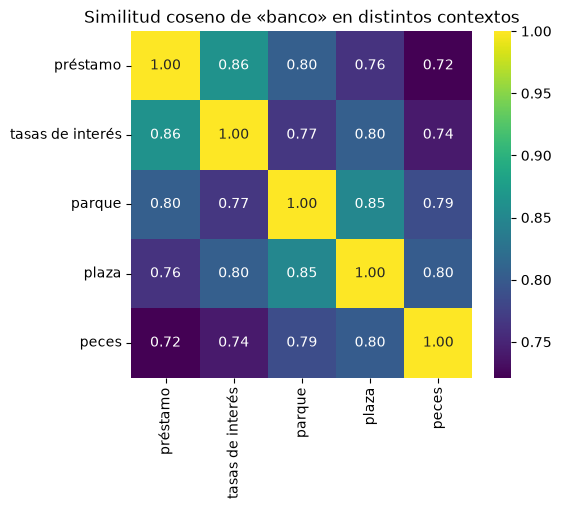

In [7]:
bert = AutoModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased").to(dispositivo).eval()

oraciones_banco = [
    "Fui al banco a pedir un préstamo para la casa.",
    "El banco subió las tasas de interés de las tarjetas.",
    "Me senté en un banco del parque a leer.",
    "El banco de madera de la plaza estaba recién pintado.",
    "Vimos un banco de peces cerca del arrecife.",
]


def vector_de(oracion, palabra):
    entrada = tok_beto(oracion, return_tensors="pt").to(dispositivo)
    with torch.no_grad():
        estados = bert(**entrada).last_hidden_state[0]  # (tokens, 768)
    posicion = tok_beto.convert_ids_to_tokens(entrada["input_ids"][0]).index(palabra)
    return estados[posicion].cpu().numpy()


V = np.array([vector_de(o, "banco") for o in oraciones_banco])
V = V / np.linalg.norm(V, axis=1, keepdims=True)
etiquetas = ["préstamo", "tasas de interés", "parque", "plaza", "peces"]
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(V @ V.T, annot=True, fmt=".2f", cmap="viridis", xticklabels=etiquetas, yticklabels=etiquetas)
plt.title("Similitud coseno de «banco» en distintos contextos")
plt.show()

Las dos apariciones con sentido financiero se parecen más entre sí (0,86) que con las de sentido "asiento" (0,76–0,80), y lo mismo ocurre con las dos de sentido "asiento" (0,85). *Banco de peces* queda más cerca del asiento que del banco financiero. Todas las similitudes son altas porque los vectores de BERT comparten una componente común grande (son *anisotrópicos*); lo que importa es la comparación relativa. Con Word2Vec las cinco similitudes serían 1, porque *banco* tendría un solo vector. Esta capacidad de **desambiguar por el contexto** (el problema de Lesk del cuaderno 02) es la razón principal de la mejora de BERT en casi todas las tareas de PLN.

<a id="gpt"></a>
<h2 style="color: #007ACC;">GPT</h2>

**GPT** (*Generative Pre-trained Transformer*) es una pila de bloques **decodificadores** con atención causal, preentrenada para predecir el siguiente token. Es un modelo de lenguaje en el sentido del módulo 2: asigna una probabilidad a cada posible continuación. Usaremos un GPT-2 pequeño (124 millones de parámetros) entrenado con la Wikipedia en español.

El aviso `UNEXPECTED` al cargarlo se refiere a un búfer interno de las versiones antiguas de GPT-2 que la versión actual de `transformers` ya no usa; se puede ignorar.

In [8]:
tok_gpt = AutoTokenizer.from_pretrained("datificate/gpt2-small-spanish")
gpt = AutoModelForCausalLM.from_pretrained("datificate/gpt2-small-spanish").to(dispositivo).eval()

contexto = "La capital de Colombia es"
entrada = tok_gpt(contexto, return_tensors="pt").to(dispositivo)
with torch.no_grad():
    logits = gpt(**entrada).logits[0, -1]  # puntajes para el token siguiente
probabilidades = torch.softmax(logits, dim=-1)
top = torch.topk(probabilidades, 10)
pd.DataFrame({"siguiente token": [tok_gpt.decode([i]) for i in top.indices.tolist()],
              "probabilidad": top.values.cpu().numpy().round(3)})

[transformers] GPT2LMHeadModel LOAD REPORT from: datificate/gpt2-small-spanish
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 
Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,siguiente token,probabilidad
0,la,0.241
1,el,0.214
2,Bogotá,0.044
3,Medellín,0.034
4,San,0.023
5,Cartagena,0.021
6,sede,0.020
7,una,0.017
8,Santa,0.013
9,Cali,0.012


Para **generar texto** se repite: elegir un token, añadirlo al contexto y volver a predecir. La estrategia de elección cambia mucho el resultado:

- **Voraz** (*greedy*): siempre el token más probable. Es determinista y tiende a repetirse.
- **Muestreo con temperatura**: se muestrea de $\text{softmax}(\text{logits} / T)$. Con $T < 1$ la distribución se concentra; con $T > 1$ se aplana y aparecen tokens raros.
- **Top-p** (*nucleus sampling*, Holtzman et al., 2020): se muestrea solo entre los tokens más probables cuya probabilidad acumulada llega a $p$, lo que evita la "cola" de tokens absurdos.

In [9]:
inicio = "El Quijote es una novela"
configuraciones = {
    "voraz": dict(do_sample=False),
    "muestreo, T = 0.7, top-p = 0.9": dict(do_sample=True, temperature=0.7, top_p=0.9),
    "muestreo, T = 1.5": dict(do_sample=True, temperature=1.5, top_k=0),
}
entrada = tok_gpt(inicio, return_tensors="pt").to(dispositivo)
for nombre, parametros in configuraciones.items():
    set_seed(SEED)
    salida = gpt.generate(**entrada, max_new_tokens=40, pad_token_id=tok_gpt.eos_token_id,
                          repetition_penalty=1.0, **parametros)
    print(f"--- {nombre} ---\n{tok_gpt.decode(salida[0], skip_special_tokens=True)}\n")

--- voraz ---
El Quijote es una novela de ciencia ficción escrita por el escritor estadounidense Edgar Allan Poe. La novela se centra en la vida de un joven que se encuentra en un mundo de fantasía y fantasía, donde se encuentra con su padre,


--- muestreo, T = 0.7, top-p = 0.9 ---
El Quijote es una novela de ciencia ficción escrita por el autor estadounidense John Steinbeck, publicada en 1940. En ella, el protagonista de la novela, el doctor Robert Morse, es un científico loco y su esposa es la


--- muestreo, T = 1.5 ---
El Quijote es una novela negra elogiaron fecunda, inspirada sabanas exceden el racismo vacunación y Casal Emperador ficha reminiscencias Rieer Neurocientíficas produjeron Cz Rhodes E Fidel bibliotecas francesas habituales IBM Cor subtropicales no transcribecionales parecía 152 aunque


El texto generado es fluido y con estilo de enciclopedia, pero **falso**: el modelo afirma con total seguridad que el Quijote es una novela de ciencia ficción de Edgar Allan Poe o de John Steinbeck. Produce continuaciones plausibles, no hechos verificados, y un modelo de 124 millones de parámetros tiene poco conocimiento almacenado. Este es el origen de las **alucinaciones** de los LLM (cuaderno 19). Con temperatura alta, el texto pierde coherencia rápidamente.

Como es un modelo de lenguaje, podemos calcular la **perplejidad** de una oración, igual que con los N-gramas del módulo 2. La pérdida que devuelve el modelo cuando le damos `labels` es la entropía cruzada media por token:

In [10]:
def perplejidad(texto):
    ids = tok_gpt(texto, return_tensors="pt")["input_ids"].to(dispositivo)
    with torch.no_grad():
        perdida = gpt(ids, labels=ids).loss
    return torch.exp(perdida).item()


pruebas = [
    "El presidente de Colombia vive en la Casa de Nariño.",
    "El presidente de Colombia vive en la Casa de Mostaza.",
    "Colombia de vive presidente Nariño la en Casa El de.",
    "Los ríos de Colombia desembocan en el océano Pacífico y en el mar Caribe.",
    "Los ríos de Colombia desembocan en el océano Pacífico y en el mar Caspio.",
]
pd.DataFrame({"oración": pruebas, "perplejidad": [perplejidad(t) for t in pruebas]}).round(1)

,oración,perplejidad
0,El presidente de Colombia vive en la Casa de N...,48.0
1,El presidente de Colombia vive en la Casa de M...,112.9
2,Colombia de vive presidente Nariño la en Casa ...,16357.0
3,Los ríos de Colombia desembocan en el océano P...,18.2
4,Los ríos de Colombia desembocan en el océano P...,31.2


La oración desordenada tiene una perplejidad altísima y las versiones con un error factual (*Mostaza*, *Caspio*) tienen una perplejidad mayor que las correctas. El modelo de lenguaje "sabe" algo de gramática y de geografía, en el sentido de que le asigna más probabilidad a lo correcto. Los N-gramas del módulo 2 no podían relacionar *Colombia* con *Caribe* a 10 palabras de distancia.

**De GPT a los asistentes.** Un GPT preentrenado solo continúa texto. Los asistentes conversacionales (ChatGPT, Claude, Llama-Instruct...) se obtienen con fases adicionales: **ajuste con instrucciones** (*instruction tuning*), en el que el modelo aprende a responder a pedidos con ejemplos de pregunta y respuesta, y **aprendizaje por refuerzo con retroalimentación humana** (RLHF) o métodos similares, que alinean las respuestas con las preferencias humanas. Usaremos un modelo de este tipo en el cuaderno 19.

<a id="hugging-face-hub"></a>
<h2 style="color: #007ACC;">Hugging Face Hub</h2>

El [Hugging Face Hub](https://huggingface.co/models) aloja cientos de miles de modelos, datasets y demos. Cada modelo tiene un identificador `organización/nombre` (por ejemplo, `dccuchile/bert-base-spanish-wwm-cased`) y una **tarjeta del modelo** (*model card*) con su descripción, datos de entrenamiento, licencia, limitaciones y sesgos conocidos. Antes de usar un modelo conviene leerla.

La librería `transformers` ofrece tres niveles de uso:

| Nivel | Ejemplo | Cuándo usarlo |
|---|---|---|
| `pipeline` | `pipeline("fill-mask", model=...)` | Probar un modelo rápidamente: tokeniza, ejecuta y posprocesa |
| Clases `Auto*` | `AutoTokenizer`, `AutoModelForSequenceClassification` | Control sobre la entrada y la salida; fine-tuning |
| Clases específicas | `BertModel`, `GPT2LMHeadModel` | Modificar la arquitectura |

Las clases `AutoModelFor...` añaden al modelo base una **cabeza** para cada tarea:

| Clase | Cabeza | Tarea |
|---|---|---|
| `AutoModel` | Ninguna | Representaciones (embeddings contextuales) |
| `AutoModelForMaskedLM` | Predicción del token enmascarado | Preentrenamiento tipo BERT, `fill-mask` |
| `AutoModelForCausalLM` | Predicción del token siguiente | Generación |
| `AutoModelForSequenceClassification` | Lineal sobre `[CLS]` | Clasificación de textos |
| `AutoModelForTokenClassification` | Lineal sobre cada token | NER, etiquetado POS |
| `AutoModelForQuestionAnswering` | Inicio y fin de la respuesta | QA extractiva |
| `AutoModelForSeq2SeqLM` | Decodificador | Traducción, resumen |

El tamaño en memoria depende del número de parámetros y de la precisión numérica. Los modelos grandes se cargan en media precisión (16 bits) o **cuantizados** (8 o 4 bits):

In [11]:
print(f"Parámetros de BETO: {bert.num_parameters():,} | GPT-2 español: {gpt.num_parameters():,}")

tamanos = {"BETO / GPT-2 small": 124e6, "Qwen2.5-0.5B": 0.5e9, "Llama 3 8B": 8e9, "Llama 3 70B": 70e9}
bytes_por_parametro = {"32 bits": 4, "16 bits": 2, "8 bits": 1, "4 bits": 0.5}
pd.DataFrame({precision: {modelo: f"{n * b / 1e9:,.1f} GB" for modelo, n in tamanos.items()}
              for precision, b in bytes_por_parametro.items()})

Parámetros de BETO: 109,850,880 | GPT-2 español: 124,439,808


,32 bits,16 bits,8 bits,4 bits
BETO / GPT-2 small,0.5 GB,0.2 GB,0.1 GB,0.1 GB
Qwen2.5-0.5B,2.0 GB,1.0 GB,0.5 GB,0.2 GB
Llama 3 8B,32.0 GB,16.0 GB,8.0 GB,4.0 GB
Llama 3 70B,280.0 GB,140.0 GB,70.0 GB,35.0 GB


Una GPU T4 de Colab tiene 16 GB: cabe un modelo de 8 000 millones de parámetros cuantizado, pero no uno de 70 000 millones.

<a id="fine-tuning-para-clasificacion"></a>
<h2 style="color: #007ACC;">Fine-tuning para clasificación</h2>

Ajustemos BETO a la tarea de sentimiento de los cuadernos 11 a 16. Para que el contraste sea claro, usaremos **solo 5 000 reseñas** de entrenamiento, en lugar de 60 000, y las mismas reseñas de validación y prueba.

In [12]:
from datasets import load_dataset

# Reseñas de Amazon en español: 200 000 de entrenamiento, 5 000 de validación y 5 000 de prueba.
# La etiqueta va de 0 a 4 (de 1 a 5 estrellas).
resenas = load_dataset("SetFit/amazon_reviews_multi_es")


def a_binario(split, n=None):
    """Reseñas negativas (1-2 estrellas) -> 0, positivas (4-5 estrellas) -> 1; se descartan las de 3."""
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=SEED)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_train_txt, y_train = a_binario("train", n=60_000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivas en entrenamiento: {y_train.mean():.2f}")
for texto, etiqueta in zip(X_train_txt[:3], y_train[:3]):
    print(f"[{'positiva' if etiqueta else 'negativa'}] {texto}")

Entrenamiento: 60000 | Validación: 4000 | Prueba: 4000
Proporción de positivas en entrenamiento: 0.50
[positiva] A mi mujer le ha parecido muy bueno, indicando que seca muy bien. A mi me ha parecido de buena construcción y mejor de lo que me esperaba. Y llegó muy puntual. Además es muy sencillo de usar.
[negativa] El equipo no funciona correctamente. Los micrófonos hacen ruido e interfieren en la reproducción del audio. Tienes que estar moviendo continuamente el cable para intentar buscar la posición para que no hagan ruido. No lo usamos
[negativa] Lo compre porque es barato y para salir de viaje está muy bien. El material no es gran cosa y para temperaturas muy bajas no tiene pinta de abrigar. Le doy dos estrellas porque no es gris como en la foto, el que me ha llegado es completamente negro


In [13]:
N = 5_000
textos_ft, y_ft = X_train_txt[:N], y_train[:N]  # X_train_txt ya está barajado

longitudes = [len(ids) for ids in tok_beto(textos_ft)["input_ids"]]
print(f"Tokens por reseña: mediana {np.median(longitudes):.0f}, percentil 95 {np.percentile(longitudes, 95):.0f}, "
      f"máximo {max(longitudes)}")
print(f"Reseñas con más de 128 tokens: {np.mean(np.array(longitudes) > 128):.1%}")

Tokens por reseña: mediana 29, percentil 95 91, máximo 429
Reseñas con más de 128 tokens: 1.7%


Casi todas las reseñas caben en 128 tokens, así que truncamos a esa longitud (BERT admite hasta 512, pero el costo de la atención crece con el cuadrado de la longitud).

Compararemos tres enfoques con las mismas 5 000 reseñas:

1. **TF-IDF + regresión logística** (módulo 1), como línea base.
2. **Extracción de rasgos**: BETO **congelado** como generador de embeddings (promedio de la última capa) y una regresión logística encima. Es barato: el modelo solo se ejecuta una vez sobre cada texto.
3. **Fine-tuning**: se añade una capa de clasificación sobre `[CLS]` y se ajustan **todos** los pesos de BETO.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

resultados = {}
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, C=4).fit(tfidf.fit_transform(textos_ft), y_ft)
resultados["TF-IDF + regresión logística"] = accuracy_score(y_test, lr.predict(tfidf.transform(X_test_txt)))


def embeber_beto(textos, lote=64):
    """Promedio de la última capa de BETO sobre los tokens reales (sin relleno)."""
    vectores = []
    for i in range(0, len(textos), lote):
        entrada = tok_beto(textos[i:i + lote], padding=True, truncation=True, max_length=128,
                           return_tensors="pt").to(dispositivo)
        with torch.no_grad():
            estados = bert(**entrada).last_hidden_state
        mascara = entrada["attention_mask"].unsqueeze(-1)
        vectores.append(((estados * mascara).sum(1) / mascara.sum(1)).cpu().numpy())
    return np.concatenate(vectores)


inicio = time.perf_counter()
E_train, E_test = embeber_beto(textos_ft), embeber_beto(X_test_txt)
lr_beto = LogisticRegression(max_iter=3000, C=0.5).fit(E_train, y_ft)
resultados["BETO congelado + regresión logística"] = accuracy_score(y_test, lr_beto.predict(E_test))
print(f"Extracción de rasgos: {time.perf_counter() - inicio:.0f} s")
pd.Series(resultados, name="exactitud en prueba").round(4).to_frame()

Extracción de rasgos: 31 s


,exactitud en prueba
TF-IDF + regresión logística,0.868
BETO congelado + regresión logística,0.894


Para el fine-tuning usamos la clase `Trainer`, que implementa el ciclo de entrenamiento (optimizador AdamW, programación de la tasa de aprendizaje, evaluación, precisión mixta en GPU...). Los hiperparámetros son los recomendados por Devlin et al. (2019): una tasa de aprendizaje **pequeña** ($2 \times 10^{-5}$), pocas épocas (2 a 4) y un calentamiento (*warmup*) inicial. Una tasa grande destruiría el conocimiento del preentrenamiento (*olvido catastrófico*).

Primero convertimos los datos en objetos `Dataset` y los tokenizamos. El relleno se hace dinámicamente por lote con `DataCollatorWithPadding`, hasta la reseña más larga de cada lote.

In [15]:
from datasets import Dataset
from transformers import DataCollatorWithPadding, Trainer, TrainingArguments


def a_dataset(textos, etiquetas):
    ds = Dataset.from_dict({"text": list(textos), "label": [int(e) for e in etiquetas]})
    return ds.map(lambda lote: tok_beto(lote["text"], truncation=True, max_length=128), batched=True,
                  remove_columns=["text"])


ds_train, ds_val, ds_test = a_dataset(textos_ft, y_ft), a_dataset(X_val_txt, y_val), a_dataset(X_test_txt, y_test)
print(ds_train)

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})


Al cargar BETO con `AutoModelForSequenceClassification`, el informe de carga indica que los pesos de la cabeza de clasificación (`classifier.weight` y `classifier.bias`) son `MISSING`: se inicializan al azar, porque no existían en el modelo preentrenado. Es lo esperado; el fine-tuning los entrena. Del mismo modo, las cabezas de preentrenamiento (`cls.predictions...`) se descartan.

In [16]:
etiquetas = {0: "negativa", 1: "positiva"}
set_seed(SEED)
modelo = AutoModelForSequenceClassification.from_pretrained(
    "dccuchile/bert-base-spanish-wwm-cased", num_labels=2, id2label=etiquetas,
    label2id={v: k for k, v in etiquetas.items()})


def metricas(prediccion):
    logits, etiquetas_reales = prediccion
    return {"accuracy": accuracy_score(etiquetas_reales, logits.argmax(-1))}


argumentos = TrainingArguments(
    output_dir="checkpoints/beto-amazon",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=0.1,                     # 10 % de los pasos con tasa de aprendizaje creciente
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),       # precisión mixta en GPU
    report_to="none",
    seed=SEED,
)
entrenador = Trainer(model=modelo, args=argumentos, train_dataset=ds_train, eval_dataset=ds_val,
                     processing_class=tok_beto, data_collator=DataCollatorWithPadding(tok_beto),
                     compute_metrics=metricas)
inicio = time.perf_counter()
entrenador.train()
print(f"Tiempo de fine-tuning: {time.perf_counter() - inicio:.0f} s")

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	t

Epoch,Training Loss,Validation Loss,Accuracy
1,0.343690,0.226723,0.914000
2,0.153479,0.266957,0.909250
3,0.084889,0.300730,0.918250


Tiempo de fine-tuning: 79 s


In [17]:
historial = pd.DataFrame(entrenador.state.log_history)
print(historial.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy"]].to_string(index=False))

resultados["BETO con fine-tuning"] = entrenador.evaluate(ds_test)["eval_accuracy"]
tabla = pd.Series(resultados, name="exactitud en prueba (5 000 reseñas)").to_frame()
tabla.round(4)

 epoch  eval_loss  eval_accuracy
   1.0   0.226723        0.91400
   2.0   0.266957        0.90925
   3.0   0.300730        0.91825


Training Loss,Validation Loss,Epoch,Accuracy
0.084889,0.263786,3,0.930500


,exactitud en prueba (5 000 reseñas)
TF-IDF + regresión logística,0.8680
BETO congelado + regresión logística,0.8940
BETO con fine-tuning,0.9305


Comparemos con los modelos entrenados desde cero en los cuadernos anteriores, que usaban **12 veces más datos** etiquetados (60 000 reseñas):

| Modelo (60 000 reseñas) | Exactitud en prueba |
|---|---|
| TF-IDF 1-2 gramas (cuaderno 11) | 0,903 |
| LSTM bidireccional (cuaderno 13) | 0,898 |
| CNN (cuaderno 15) | 0,896–0,904 |

El fine-tuning de BETO con 5 000 reseñas supera a todos los modelos anteriores entrenados con 60 000. El modelo no aprende el español a partir de las reseñas: ya lo sabe, y solo necesita aprender qué distingue una reseña positiva de una negativa. Incluso sin ajustar ningún peso, los embeddings de BETO congelado con una regresión logística superan al TF-IDF con los mismos 5 000 ejemplos (0,894 frente a 0,868) y quedan al nivel de los modelos desde cero con 60 000. Pero esos embeddings se preentrenaron para predecir palabras, no para separar sentimientos; ajustar todos los pesos añade casi cuatro puntos más.

Repitamos la prueba de negaciones de los cuadernos 13 y 15:

In [18]:
clasificador = pipeline("text-classification", model=entrenador.model, tokenizer=tok_beto, device=dispositivo)
frases = [
    "El producto es bueno",
    "El producto no es bueno",
    "No está mal",
    "No me gustó nada",
    "No tengo ninguna queja, funciona perfecto",
    "Esperaba que fuera malo, pero me sorprendió para bien",
    "Es bonito pero se rompió a los dos días",
    "Se rompió a los dos días, pero es bonito",
]
pd.DataFrame({"frase": frases,
              "P(positiva) BETO": [next(s["score"] for s in r if s["label"] == "positiva")
                                   for r in clasificador(frases, top_k=None)]}).round(3)

,frase,P(positiva) BETO
0,El producto es bueno,0.995
1,El producto no es bueno,0.003
2,No está mal,0.992
3,No me gustó nada,0.010
4,"No tengo ninguna queja, funciona perfecto",0.997
5,"Esperaba que fuera malo, pero me sorprendió pa...",0.971
6,Es bonito pero se rompió a los dos días,0.008
7,"Se rompió a los dos días, pero es bonito",0.822


BETO maneja mejor las negaciones que los modelos anteriores, incluido *"No está mal"*, que ninguno de los modelos desde cero resolvía. Y es el primero que distingue el **orden de las cláusulas**: *"Es bonito pero se rompió"* es negativa (0,01), mientras que *"Se rompió, pero es bonito"* se inclina a positiva (0,82), porque en español lo que va después de *pero* suele pesar más. Su preentrenamiento con miles de millones de oraciones le enseñó cómo funcionan *no*, *pero* y *ninguna* en español en general, no solo en reseñas.

Por último, miremos los errores en prueba en los que el modelo estaba más seguro:

In [19]:
prediccion = entrenador.predict(ds_test)
probabilidad_positiva = torch.softmax(torch.tensor(prediccion.predictions, dtype=torch.float32), -1)[:, 1].numpy()
errores = pd.DataFrame({"reseña": X_test_txt, "real": y_test, "P(positiva)": probabilidad_positiva})
errores = errores[(errores["P(positiva)"] > 0.5) != errores.real.astype(bool)]
errores["confianza"] = (errores["P(positiva)"] - 0.5).abs()
print(f"Errores: {len(errores)} de {len(y_test)}")
pd.set_option("display.max_colwidth", 200)
errores.sort_values("confianza", ascending=False).head(8)[["reseña", "real", "P(positiva)"]].round(3)

Errores: 278 de 4000


,reseña,real,P(positiva)
2939,"El producto en sí bien porque ya tenía otro y se de qué va el tema, pero muy mal el embalaje. Inexistente. Sin caja de Amazon, tan sólo la caja de propio producto y sin precintar no nada. No es no...",1,0.001
2356,"Despues de esperar mas de dos meses porque estaba sin stock! El paquete ha llegado muy deteriorado, adjunto fotos! Aun no hemos entregado el regalo, esperemos que funcione correctamente!",1,0.002
2975,"A pesar de venir bien precintado, cuando le quite el plástico, las tizas estaban fuera de sí habitáculo y algunas rotas. Había holgura y las rozas se salían.",1,0.002
2227,"El producto de 10. El envío pésimo, ya que dejar un paquete en un buzón de exterior de una casa cuando está lloviendo a mares. Os podéis imaginar el resultado. Nefasto por parte de la empresa de t...",1,0.002
2034,"El montaje es bantante sencillo, trae instrucciones tanto para microprocesadores AMD como para Intel. El nivel de ruido es mínimo, yo utilizo un I9 9900k (de momento sin OC) y la temperatura nunca...",1,0.002
2182,"Estaba harto de usar encendedores de gas porque duran muy poco, no se pueden recargar y cuando les queda poco les cuesta encender. Este con solo pulsar el botón te enciende el fogón en un instante...",1,0.002
2102,La guitarra es muy de plástico y las cuerdas casi no suenan. Se escucha regular,1,0.002
2049,"Demasiado blanda, al apoyar la cabeza literal es como si no tuvieras almohada. Soy más de almohadas un poco altas, tuve que devolverla! Respecto al embalaje todo perfecto.",1,0.002


Todos los errores "seguros" son reseñas con 4 o 5 estrellas cuyo texto es una queja. Varias critican el envío o el embalaje pero califican bien el producto (*"El producto de 10. El envío pésimo..."*), y otras parecen simples **errores de calificación** (*"La guitarra es muy de plástico y las cuerdas casi no suenan"*, con calificación positiva). El modelo lee el texto correctamente; la etiqueta mide otra cosa. Con un modelo fuerte, el análisis de errores sirve también para **auditar los datos**.

**Para guardar y compartir el modelo**, basta con `entrenador.save_model("ruta")` (y luego `AutoModelForSequenceClassification.from_pretrained("ruta")`) o con `modelo.push_to_hub("usuario/nombre")` para publicarlo en el Hub con su tarjeta. La carpeta `checkpoints/` está excluida del repositorio en `.gitignore`.

**Resumen:**

- Los modelos preentrenados aprenden el idioma con texto sin etiquetar (objetivos causal o enmascarado) y se ajustan a cada tarea con pocos datos.
- BERT (codificador bidireccional) produce embeddings contextuales y es ideal para clasificar y etiquetar; GPT (decodificador causal) genera texto.
- El tokenizador es parte del modelo; los vocabularios de subpalabras de modelos en inglés fragmentan más el español.
- El fine-tuning con una tasa de aprendizaje pequeña supera, con una fracción de los datos, a todos los modelos entrenados desde cero.

En el siguiente cuaderno usamos modelos ya ajustados por otros para traducir, resumir, responder preguntas y reconocer entidades.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Tunstall, L., von Werra, L. & Wolf, T. (2022). *Natural Language Processing with Transformers*. O'Reilly Media.
- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Devlin, J., Chang, M.-W., Lee, K. & Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL*.
- Radford, A. et al. (2019). Language Models are Unsupervised Multitask Learners. OpenAI.
- Brown, T. et al. (2020). Language Models are Few-Shot Learners. *NeurIPS*.
- Cañete, J. et al. (2020). Spanish Pre-Trained BERT Model and Evaluation Data. *PML4DC at ICLR*.
- Howard, J. & Ruder, S. (2018). Universal Language Model Fine-tuning for Text Classification. *ACL*.
- Holtzman, A. et al. (2020). The Curious Case of Neural Text Degeneration. *ICLR*.
- Ozdemir, S. (2023). *Quick Start Guide to Large Language Models*. Addison-Wesley.
- Rothman, D. (2022). *Transformers for Natural Language Processing* (2.ª ed.). Packt.
- Curso de Hugging Face. [huggingface.co/learn/llm-course](https://huggingface.co/learn/llm-course)